In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"


import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
import seaborn as sns


In [2]:
df = pd.read_csv("./datasets/iris.csv")

In [3]:
# df
X = df.drop(['Id', 'Species'], axis=1)
y = df['Species']

In [4]:
scaler = StandardScaler()
le = LabelEncoder()

In [5]:
#scaling teh data
X_scaled = scaler.fit_transform(X)
y_encoded = le.fit_transform(y)
# y_encoded

In [6]:
# print(X_scaled)
type(X_scaled)

numpy.ndarray

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

In [8]:
# X_scaled = pd.DataFrame(
#     X_scaled,
#     columns=X.columns
# )

# X_scaled.head()

<Axes: >

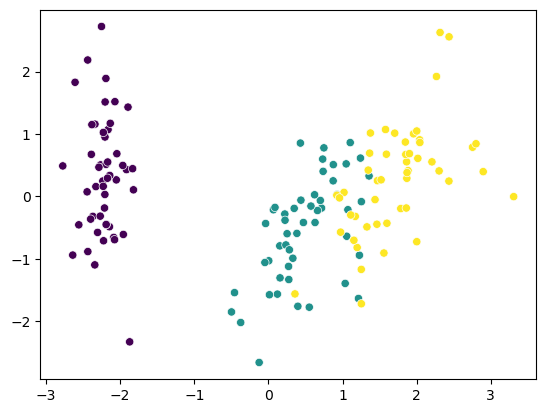

In [9]:
# sns.scatterplot(x=X_scaled[:,0], y=X_scaled[:, 1], c=y_encoded)
sns.scatterplot(x=pca_data[:,0], y=pca_data[:, 1], c=y_encoded)

In [10]:
from sklearn.cluster import KMeans

In [11]:
#elbow method

wcss = []

for k in range (1, 11):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(pca_data)
    wcss.append(kmeans.inertia_)

<Axes: >

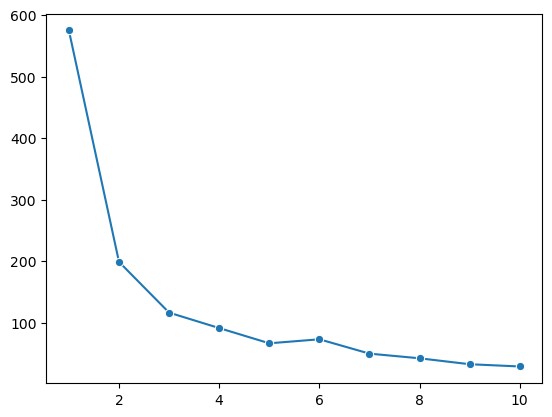

In [12]:
sns.lineplot(x=range(1, 11), y=wcss, marker='o')

<Axes: >

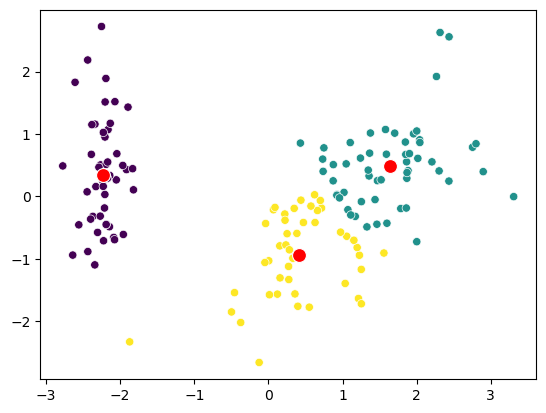

In [14]:
#plotting with k means

kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:,0], y=pca_data[:, 1], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], marker='o', c='red', s=100)